# Mini Project: Perform Multiple Linear Regression

## Overview
This project focuses on using multiple linear regression to analyze the relationship between sales and various marketing promotion strategies. By leveraging multiple independent variables, such as TV, social media, radio, and influencer promotions, we aim to build a predictive model that estimates sales based on these factors. This project will cover the complete data science pipeline, including data exploration, preprocessing, model building, evaluation, and interpretation.

## Objective
Develop a multiple linear regression model to predict sales based on marketing promotion data. The project will involve exploring the dataset, selecting relevant independent variables, fitting the model, checking assumptions, and interpreting the results to provide actionable insights.

## Learning Outcomes
1. Understand the concept of multiple linear regression and its applications.
2. Learn to preprocess and explore data for regression analysis.
3. Gain experience in fitting and evaluating a multiple linear regression model.
4. Check and validate regression assumptions.
5. Interpret model coefficients and communicate results to stakeholders.

---


## Step 1: Define the Problem
### Task:
Understand the problem and its real-world implications. The goal is to predict sales based on various marketing promotion strategies, which can help the business optimize its marketing efforts and allocate resources effectively.

### Mini-task:
Write a brief paragraph on how predicting sales using multiple linear regression can benefit the business.

---
Predicting Sales in this context using multiple Linear Regression enhances the possibility of having different factors that could lead to making a great sales for the company rather than using and/or depending only on one factor which may not be yielding enough sales when compared to using multiple independent factors/variables. Again, using multiple variables will tend to improve how the model will fit to the dataset to yield even higher margins.


## Step 2: Data Collection
### Task:
Collect the dataset required for building the regression model. The dataset used in this project is `marketing_sales_data.csv`, which contains information about TV, social media, radio, and influencer promotions, along with sales data.

### Mini-task:
Load the dataset and inspect the first few rows to understand its structure.

#### Hint:
Use the `pandas` library to load the dataset and display the first five rows.

```python
import pandas as pd

# Load the dataset
data = pd.read_csv('marketing_sales_data.csv')

# Display the first five rows
### YOUR CODE HERE ###
```

---

In [71]:
# Import Data Files from Google Drive

import requests
import pandas as pd
from io import StringIO
def read_gd(sharingurl):
    file_id = sharingurl.split('/')[-2]
    download_url='https://drive.google.com/uc?export=download&id=' + file_id
    url = requests.get(download_url).text
    csv_raw = StringIO(url)
    return csv_raw

url = "https://drive.google.com/file/d/1WChLou3qt_JaPjYLZBMHJ8WxSssQ-enL/view?usp=drive_link"
gdd = read_gd(url)

df = pd.read_csv(gdd)

df.head()

,TV,Radio,Social Media,Influencer,Sales
0,Low,3.518070,2.293790,Micro,55.261284
1,Low,7.756876,2.572287,Mega,67.574904
2,High,20.348988,1.227180,Micro,272.250108
3,Medium,20.108487,2.728374,Mega,195.102176
4,High,31.653200,7.776978,Nano,273.960377


In [72]:
df.rename(columns={'Social Media': 'Social_Media'}, inplace=True)
df.head()

,TV,Radio,Social_Media,Influencer,Sales
0,Low,3.518070,2.293790,Micro,55.261284
1,Low,7.756876,2.572287,Mega,67.574904
2,High,20.348988,1.227180,Micro,272.250108
3,Medium,20.108487,2.728374,Mega,195.102176
4,High,31.653200,7.776978,Nano,273.960377


In [73]:
# Let us get the statistical display of our model

df.describe()

,Radio,Social_Media,Sales
count,572.000000,572.000000,572.000000
mean,17.520616,3.333803,189.296908
std,9.290933,2.238378,89.871581
min,0.109106,0.000031,33.509810
25%,10.699556,1.585549,118.718722
50%,17.149517,3.150111,184.005362
75%,24.606396,4.730408,264.500118
max,42.271579,11.403625,357.788195


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 572 entries, 0 to 571
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            572 non-null    object 
 1   Radio         572 non-null    float64
 2   Social_Media  572 non-null    float64
 3   Influencer    572 non-null    object 
 4   Sales         572 non-null    float64
dtypes: float64(3), object(2)
memory usage: 22.5+ KB


In [75]:
df_num = df[['Radio', 'Social_Media', 'Sales']]
df_obj = df[['TV', 'Influencer']]
df_obj

,TV,Influencer
0,Low,Micro
1,Low,Mega
2,High,Micro
3,Medium,Mega
4,High,Nano
...,...,...
567,Medium,Micro
568,High,Mega
569,Medium,Nano
570,Medium,Macro


## Step 3: Exploratory Data Analysis (EDA)
### Task:
Analyze the dataset to understand the distribution of variables, identify relationships between variables, and prepare the data for modeling.

### Mini-task:
Create a pairplot to visualize the relationships between continuous variables in the dataset.

#### Hint:
Use `seaborn.pairplot()` to create a pairplot of the continuous variables.

```python
import seaborn as sns

# Create a pairplot of the continuous variables
### YOUR CODE HERE ###
```

---

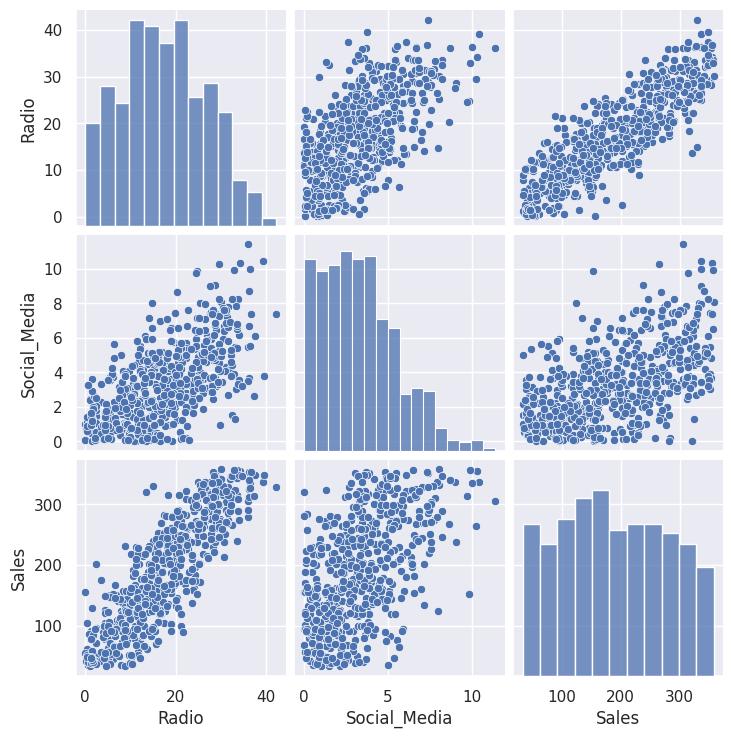

In [76]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

sns.pairplot(df_num)


## Step 4: Data Preparation
### Task:
Prepare the data for regression analysis by handling missing values, encoding categorical variables, and splitting the data into training and testing sets.

### Mini-task:
Drop rows with missing values and encode categorical variables if necessary.

#### Hint:
Use `data.dropna()` to remove rows with missing values and `pd.get_dummies()` to encode categorical variables.

```python
# Drop rows with missing values
### YOUR CODE HERE ###

# Encode categorical variables (if needed)
### YOUR CODE HERE ###
```

---

In [77]:
df.isna().sum()
df.dropna(inplace=True)
df

,TV,Radio,Social_Media,Influencer,Sales
0,Low,3.518070,2.293790,Micro,55.261284
1,Low,7.756876,2.572287,Mega,67.574904
2,High,20.348988,1.227180,Micro,272.250108
3,Medium,20.108487,2.728374,Mega,195.102176
4,High,31.653200,7.776978,Nano,273.960377
...,...,...,...,...,...
567,Medium,14.656633,3.817980,Micro,191.521266
568,High,28.110171,7.358169,Mega,297.626731
569,Medium,11.401084,5.818697,Nano,145.416851
570,Medium,21.119991,5.703028,Macro,209.326830


In [78]:
# From the above observation, we can see that there are n missing values. Therefore, we go ahead and encode our categorical variables
# Encode categorical variables

df_obj = pd.get_dummies(df_obj, drop_first=True, dtype='int')
df_obj

,TV_Low,TV_Medium,Influencer_Mega,Influencer_Micro,Influencer_Nano
0,1,0,0,1,0
1,1,0,1,0,0
2,0,0,0,1,0
3,0,1,1,0,0
4,0,0,0,0,1
...,...,...,...,...,...
567,0,1,0,1,0
568,0,0,1,0,0
569,0,1,0,0,1
570,0,1,0,0,0


In [79]:
df_cat = pd.concat((df_num, df_obj), axis=1)
df_cat

,Radio,Social_Media,Sales,TV_Low,TV_Medium,Influencer_Mega,Influencer_Micro,Influencer_Nano
0,3.518070,2.293790,55.261284,1,0,0,1,0
1,7.756876,2.572287,67.574904,1,0,1,0,0
2,20.348988,1.227180,272.250108,0,0,0,1,0
3,20.108487,2.728374,195.102176,0,1,1,0,0
4,31.653200,7.776978,273.960377,0,0,0,0,1
...,...,...,...,...,...,...,...,...
567,14.656633,3.817980,191.521266,0,1,0,1,0
568,28.110171,7.358169,297.626731,0,0,1,0,0
569,11.401084,5.818697,145.416851,0,1,0,0,1
570,21.119991,5.703028,209.326830,0,1,0,0,0


In [80]:
# We have to map out the X and the y

import statsmodels.api as sm

X = df_cat.drop('Sales', axis=1)
y = df_cat['Sales']
print(X)
print(y)

         Radio  Social_Media  TV_Low  TV_Medium  Influencer_Mega  \
0     3.518070      2.293790       1          0                0   
1     7.756876      2.572287       1          0                1   
2    20.348988      1.227180       0          0                0   
3    20.108487      2.728374       0          1                1   
4    31.653200      7.776978       0          0                0   
..         ...           ...     ...        ...              ...   
567  14.656633      3.817980       0          1                0   
568  28.110171      7.358169       0          0                1   
569  11.401084      5.818697       0          1                0   
570  21.119991      5.703028       0          1                0   
571  13.221237      3.660566       1          0                0   

     Influencer_Micro  Influencer_Nano  
0                   1                0  
1                   0                0  
2                   1                0  
3                  

In [66]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)
X

array([[-1.50843863, -0.46503463,  1.3585916 , ..., -0.56119741,
         1.66975431, -0.61507175],
       [-1.0518089 , -0.34050683,  1.3585916 , ...,  1.78190417,
        -0.5988905 , -0.61507175],
       [ 0.30468926, -0.94196181, -0.73605637, ..., -0.56119741,
         1.66975431, -0.61507175],
       ...,
       [-0.65923281,  1.11110281, -0.73605637, ..., -0.56119741,
        -0.5988905 ,  1.62582659],
       [ 0.3877464 ,  1.05938243, -0.73605637, ..., -0.56119741,
        -0.5988905 , -0.61507175],
       [-0.46315496,  0.14610968,  1.3585916 , ..., -0.56119741,
         1.66975431, -0.61507175]])

In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train

array([[ 0.50806482,  0.92293688, -0.73605637, ...,  1.78190417,
        -0.5988905 , -0.61507175],
       [-0.21015224, -1.2492463 , -0.73605637, ..., -0.56119741,
        -0.5988905 , -0.61507175],
       [-0.60987442, -0.69139103,  1.3585916 , ...,  1.78190417,
        -0.5988905 , -0.61507175],
       ...,
       [-1.01559314, -0.29343881,  1.3585916 , ..., -0.56119741,
        -0.5988905 , -0.61507175],
       [-0.18891247, -0.09400151, -0.73605637, ..., -0.56119741,
        -0.5988905 ,  1.62582659],
       [-1.40957811, -1.32396367,  1.3585916 , ..., -0.56119741,
        -0.5988905 , -0.61507175]])

## Step 5: Model Building
### Task:
Fit a multiple linear regression model to predict sales using the selected independent variables.

### Mini-task:
Define the OLS formula and fit the model using the `statsmodels` library.

#### Hint:
Use `statsmodels.formula.api.ols()` to define the model and fit it to the data.

```python
import statsmodels.formula.api as smf

# Define the OLS formula
### YOUR CODE HERE ###

# Fit the model
### YOUR CODE HERE ###

# Display the model summary
### YOUR CODE HERE ###
```

---

In [88]:
import statsmodels.formula.api as smf

# Define the OLS formula
model = smf.ols(formula='Sales ~ Radio + Social_Media +	TV_Low + TV_Medium + Influencer_Mega + Influencer_Micro +	Influencer_Nano', data=df_cat)

# Fit the model
results = model.fit()

# Display the model summary
print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.904
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                     760.4
Date:                Sun, 27 Apr 2025   Prob (F-statistic):          1.82e-282
Time:                        15:33:33   Log-Likelihood:                -2713.4
No. Observations:                 572   AIC:                             5443.
Df Residuals:                     564   BIC:                             5478.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          217.4784      6.584  

## Step 6: Model Evaluation
### Task:
Evaluate the model by checking the regression assumptions, including linearity, independence, normality, constant variance, and multicollinearity.

### Mini-task:
Create scatterplots to check the linearity assumption and calculate the residuals to check the normality assumption.

#### Hint:
Use `seaborn.scatterplot()` to create scatterplots and `statsmodels.qqplot()` to check the normality of residuals.

```python
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Create scatterplots for linearity
### YOUR CODE HERE ###

# Calculate residuals and create a Q-Q plot
### YOUR CODE HERE ###
```

---

[]

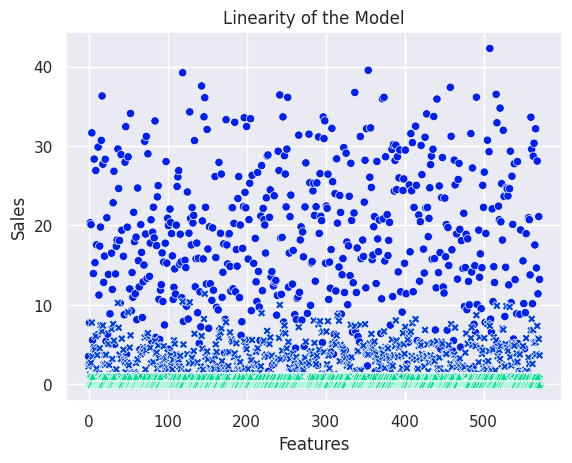

In [91]:
# To check for independence

sns.scatterplot(X, palette='winter', legend=False)
plt.title('Linearity of the Model')
plt.xlabel('Features')
plt.ylabel('Sales')
plt.plot()

[]

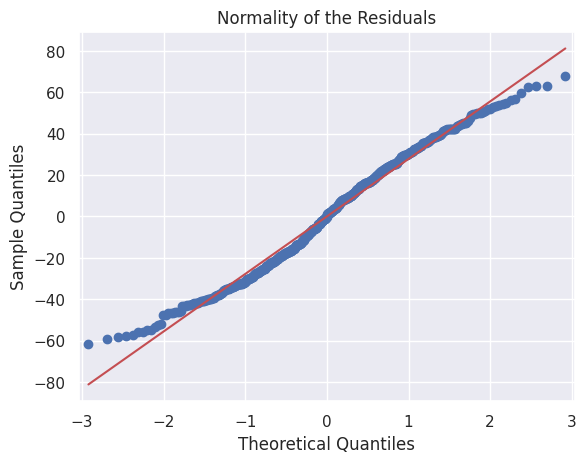

In [92]:
# To check if the residuals are normally distributes

import statsmodels.api as sm

residuals = results.resid
sm.qqplot(residuals, line='s')
plt.title('Normality of the Residuals')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.plot()

[]

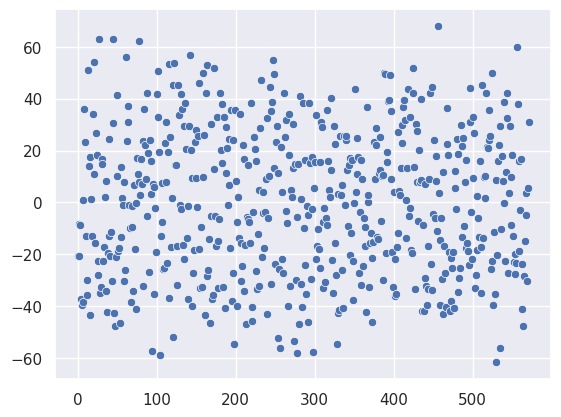

In [ ]:
sns.scatterplot(residuals)
plt.plot()

In [96]:
df_corr = df_cat.corr()
df_corr

,Radio,Social_Media,Sales,TV_Low,TV_Medium,Influencer_Mega,Influencer_Micro,Influencer_Nano
Radio,1.000000,0.629941,0.858036,-0.674203,0.004400,0.035704,0.001712,0.015640
Social_Media,0.629941,1.000000,0.542048,-0.423910,-0.008272,0.066023,-0.052077,0.028030
Sales,0.858036,0.542048,1.000000,-0.805896,0.050449,0.032443,-0.006503,0.017656
TV_Low,-0.674203,-0.423910,-0.805896,1.000000,-0.550117,-0.052697,0.016107,0.006815
TV_Medium,0.004400,-0.008272,0.050449,-0.550117,1.000000,0.067488,0.007302,-0.059374
Influencer_Mega,0.035704,0.066023,0.032443,-0.052697,0.067488,1.000000,-0.336096,-0.345177
Influencer_Micro,0.001712,-0.052077,-0.006503,0.016107,0.007302,-0.336096,1.000000,-0.368361
Influencer_Nano,0.015640,0.028030,0.017656,0.006815,-0.059374,-0.345177,-0.368361,1.000000


In [99]:
df_num_corrn = df_num.corr(method='pearson')
df_num_corrn

,Radio,Social_Media,Sales
Radio,1.000000,0.629941,0.858036
Social_Media,0.629941,1.000000,0.542048
Sales,0.858036,0.542048,1.000000


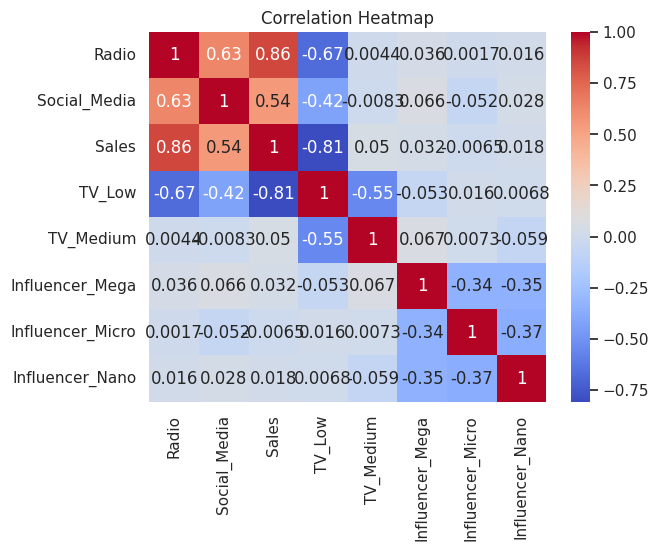

In [100]:
corr = df_cat.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


## Step 7: Results and Interpretation
### Task:
Interpret the model results, including the R-squared value, coefficients, and their statistical significance.

### Mini-task:
Display the model summary and interpret the coefficients.

#### Hint:
Use `model.summary()` to display the model results and interpret the coefficients.

```python
# Display the model summary
### YOUR CODE HERE ###

# Interpret the coefficients
### YOUR CODE HERE ###
```

---

In [93]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.904
Model:                            OLS   Adj. R-squared:                  0.903
Method:                 Least Squares   F-statistic:                     760.4
Date:                Sun, 27 Apr 2025   Prob (F-statistic):          1.82e-282
Time:                        15:42:33   Log-Likelihood:                -2713.4
No. Observations:                 572   AIC:                             5443.
Df Residuals:                     564   BIC:                             5478.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept          217.4784      6.584  

In [95]:
# From the model summary, it can be deduced that
# 1) Our model was good at explaining the variability in the independent variable as can be seen in the Adj. R-Squared which is 90.3%.

# A positive coefficient is seen in  i) Influencer_Mega, Influencer_Micro, Influencer_Nano, and Radio which indicates that more Influencer adverts and Radio Ads
# will mostly increase Sales than other variables.

# Again, adding Radio and Social_Media will help to refine our model.


## Considerations
**What are some key takeaways you learned from this project?**
- Reflect on the importance of checking regression assumptions and interpreting model coefficients.
- Consider how the model's insights can be used to optimize marketing strategies.

**How would you share your findings with a team?**
- Prepare a presentation with visualizations and key metrics.
- Discuss the impact of different marketing strategies on sales.

**What would you share with and recommend to stakeholders?**
- Highlight the key factors that contribute most to sales.
- Recommend strategies to optimize marketing efforts based on the model's insights.

From the summary section, the Radio advert has the best Sales strategy as can be seen from the summary to have a coefficent of 2.9735  and TV_Micro with a coefficient of 2.9391